# Task 4: ResNet18 Fine-Tuning

Fine-tune `layer4` and `fc` for five epochs, starting from the baseline checkpoint.


## 1. Setup


In [2]:
from pathlib import Path
import json
import sys
import torch
import torch.nn as nn
from torchvision.models import resnet18

PROJECT_DIR = Path.cwd()
IS_KAGGLE = Path("/kaggle/input").is_dir()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RUN_FULL_FINETUNING = False
DOWNLOAD_COMPETITION_DATA = False  # Kaggle only

OUTPUT_DIR = Path("/kaggle/working") if IS_KAGGLE else PROJECT_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Environment:", "Kaggle" if IS_KAGGLE else "Local / VS Code")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Full fine-tuning enabled:", RUN_FULL_FINETUNING)

Project folder: c:\Users\yzsha\Documents\DataAndAI_project\KaggleCompetitionProject\KaggleCompetitionENGE707
Environment: Local / VS Code
Device: cpu
Full fine-tuning enabled: False


## 2. Load Baseline Checkpoint


In [3]:
# Prefer the file downloaded into the VS Code project folder.
BASELINE_CANDIDATES = [
    PROJECT_DIR / "best_resnet18.pth",
    Path("/kaggle/input/datasets/shawnleeyz/best-resnet18/best_resnet18.pth"),
    Path("/kaggle/working/best_resnet18.pth"),
]

baseline_path = next((p for p in BASELINE_CANDIDATES if p.is_file()), None)
if baseline_path is None:
    raise FileNotFoundError(
        "Original checkpoint missing. Put best_resnet18.pth in PROJECT_DIR "
        "or attach the baseline checkpoint Kaggle dataset."
    )

baseline_checkpoint = torch.load(
    baseline_path, map_location="cpu", weights_only=True
)
needed_keys = {"model_state_dict", "class_to_idx", "epoch", "val_accuracy"}
assert needed_keys.issubset(baseline_checkpoint), "Checkpoint has missing fields"

class_to_idx = baseline_checkpoint["class_to_idx"]
num_classes = len(class_to_idx)
assert num_classes == 8, f"Expected 8 classes, found {num_classes}"

model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model.load_state_dict(baseline_checkpoint["model_state_dict"])
model = model.to(DEVICE)

baseline_val_acc = float(baseline_checkpoint["val_accuracy"])
print("Original checkpoint:", baseline_path)
print("Original saved epoch:", baseline_checkpoint["epoch"])
print(f"Original validation accuracy: {baseline_val_acc * 100:.2f}%")
print("Class mapping:", class_to_idx)

Original checkpoint: c:\Users\yzsha\Documents\DataAndAI_project\KaggleCompetitionProject\KaggleCompetitionENGE707\best_resnet18.pth
Original saved epoch: 10
Original validation accuracy: 95.98%
Class mapping: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}


## 3. Configure Fine-Tuning


In [4]:
# Freeze all parameters first; only explicitly named groups are updated.
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
for parameter in model.fc.parameters():
    parameter.requires_grad = True

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4},
])
NUM_EPOCHS = 5

trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
all_count = sum(p.numel() for p in model.parameters())
print(f"Parameters: {trainable_count:,} trainable / {all_count:,} total "
      f"({trainable_count / all_count * 100:.2f}%)")
print("Optimiser learning rates:", [g["lr"] for g in optimizer.param_groups])
print("Additional epochs:", NUM_EPOCHS)
assert all(not p.requires_grad for p in model.layer3.parameters())
assert all(p.requires_grad for p in model.layer4.parameters())
assert all(p.requires_grad for p in model.fc.parameters())

Parameters: 8,397,832 trainable / 11,180,616 total (75.11%)
Optimiser learning rates: [1e-05, 0.0001]
Additional epochs: 5


## 4. Load Dataset (when retraining)


In [5]:
# Only run this optional download on Kaggle when the flag is enabled.
if DOWNLOAD_COMPETITION_DATA:
    if not IS_KAGGLE:
        raise RuntimeError("Automatic competition download is intended for Kaggle only.")
    import subprocess
    import zipfile

    kaggle_data_dir = Path("/kaggle/working/competition_data")
    kaggle_data_dir.mkdir(parents=True, exist_ok=True)
    if not (kaggle_data_dir / "train_labels.csv").exists():
        subprocess.run([
            "kaggle", "competitions", "download", "-c",
            "enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch",
            "-p", str(kaggle_data_dir),
        ], check=True)
        for zip_path in kaggle_data_dir.glob("*.zip"):
            with zipfile.ZipFile(zip_path) as archive:
                archive.extractall(kaggle_data_dir)
    print("Competition data ready:",
          (kaggle_data_dir / "train_labels.csv").exists())
else:
    print("Competition download skipped.")

Competition download skipped.


In [6]:
# A shared path resolver for both optional training and test inference.
# Defining this function does not load data or start training.
def resolve_pipeline_and_data_dir():
    # Search only expected locations, not the entire file system.
    pipeline_candidates = [
        PROJECT_DIR / "data_pipeline.py",
        Path("/kaggle/input/datasets/shawnleeyz/pipeline/data_pipeline.py"),
    ]
    pipeline_file = next((p for p in pipeline_candidates if p.is_file()), None)
    if pipeline_file is None:
        raise FileNotFoundError(
            "data_pipeline.py was not found; place it in PROJECT_DIR "
            "or attach the Kaggle pipeline dataset."
        )

    pipeline_dir = str(pipeline_file.parent)
    if pipeline_dir not in sys.path:
        sys.path.insert(0, pipeline_dir)
    from data_pipeline import create_dataloaders

    data_candidates = [
        Path("/kaggle/working/competition_data"),
        PROJECT_DIR,
        PROJECT_DIR / "competition_data",
    ]
    data_dir = next(
        (p for p in data_candidates
         if (p / "train_labels.csv").is_file() and (p / "train").is_dir()),
        None,
    )
    if data_dir is None:
        raise FileNotFoundError(
            "Competition data not found. On Kaggle enable DOWNLOAD_COMPETITION_DATA; "
            "in VS Code set PROJECT_DIR or provide the competition_data subfolder."
        )
    return create_dataloaders, data_dir


NEED_DATALOADERS = RUN_FULL_FINETUNING
train_loader = None
val_loader = None

if NEED_DATALOADERS:
    create_dataloaders, data_dir = resolve_pipeline_and_data_dir()
    data = create_dataloaders(data_dir=data_dir)
    train_loader, val_loader = data.train_loader, data.val_loader
    assert data.class_to_idx == class_to_idx, "Class mapping differs from checkpoint"
    print("Data folder:", data_dir)
    print("Training images:", len(train_loader.dataset))
    print("Validation images:", len(val_loader.dataset))
    print("Same class mapping verified.")
else:
    print("Data loading skipped: saved weights and training history are enough for review.")


Data loading skipped: saved weights and training history are enough for review.


## 5. Training and Validation Functions


In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    # Maintain the original pretrained BatchNorm running statistics.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += batch_size

    return total_loss / total, correct / total

print("Training and validation functions defined.")

Training and validation functions defined.


## 6. Five-Epoch Fine-Tuning (optional)


In [7]:
reproduced_checkpoint_path = OUTPUT_DIR / "best_resnet18_finetuned_reproduced.pth"
reproduced_history_path = OUTPUT_DIR / "finetuning_history_reproduced.json"

if RUN_FULL_FINETUNING:
    if reproduced_checkpoint_path.exists() or reproduced_history_path.exists():
        raise FileExistsError("Reproduced output already exists. Rename/remove it "
                              "explicitly before repeating training.")

    reproduced_history = {
        "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []
    }
    best_val_accuracy = -1.0
    best_epoch = None

    for epoch in range(NUM_EPOCHS):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, DEVICE
        )
        val_loss, val_acc = validate_one_epoch(
            model, val_loader, criterion, DEVICE
        )

        for name, value in (
            ("train_loss", train_loss), ("train_acc", train_acc),
            ("val_loss", val_loss), ("val_acc", val_acc)
        ):
            reproduced_history[name].append(value)

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_epoch = epoch + 1
            torch.save({
                "model_state_dict": model.state_dict(),
                "class_to_idx": class_to_idx,
                "epoch": best_epoch,
                "val_accuracy": best_val_accuracy,
            }, reproduced_checkpoint_path)

        with reproduced_history_path.open("w", encoding="utf-8") as f:
            json.dump(reproduced_history, f, indent=2)

        print(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc * 100:.2f}%"
        )

    print(f"Best reproduced epoch: {best_epoch}")
    print(f"Best reproduced validation accuracy: {best_val_accuracy * 100:.2f}%")
    print("Saved checkpoint:", reproduced_checkpoint_path)
    print("Saved history:", reproduced_history_path)
else:
    print("Five-epoch fine-tuning skipped; no checkpoints were changed.")

Five-epoch fine-tuning skipped; no checkpoints were changed.


## 7. Saved Fine-Tuning Results


In [8]:
from IPython.display import display
import pandas as pd

history_candidates = [
    PROJECT_DIR / "finetuning_history.json",
    Path("/kaggle/working/finetuning_history.json"),
    reproduced_history_path,
]
history_file = next((p for p in history_candidates if p.is_file()), None)

finetuning_history = None
finetuning_results = None
if history_file is not None:
    with history_file.open("r", encoding="utf-8") as f:
        finetuning_history = json.load(f)
    metric_names = ("train_loss", "train_acc", "val_loss", "val_acc")
    assert all(k in finetuning_history for k in metric_names), "Missing history metrics"
    lengths = {len(finetuning_history[k]) for k in metric_names}
    assert len(lengths) == 1, "Epoch counts differ between recorded metrics"
    n_epochs = lengths.pop()

    finetuning_results = pd.DataFrame({
        "Epoch": range(1, n_epochs + 1),
        "Training loss": finetuning_history["train_loss"],
        "Training accuracy (%)": [v * 100 for v in finetuning_history["train_acc"]],
        "Validation loss": finetuning_history["val_loss"],
        "Validation accuracy (%)": [v * 100 for v in finetuning_history["val_acc"]],
    })
    print("History loaded:", history_file)
    display(finetuning_results.round(4))
else:
    print("finetuning_history.json not found. Place the downloaded file in PROJECT_DIR.")

History loaded: c:\Users\yzsha\Documents\DataAndAI_project\KaggleCompetitionProject\KaggleCompetitionENGE707\finetuning_history.json


,Epoch,Training loss,Training accuracy (%),Validation loss,Validation accuracy (%)
0,1,0.0659,97.7355,0.0778,97.4075
1,2,0.0404,98.6075,0.0432,98.5859
2,3,0.0289,98.9669,0.0515,98.3424
3,4,0.0216,99.2419,0.0383,98.7587
4,5,0.0167,99.4069,0.0412,98.6330


## 8. Learning Curves


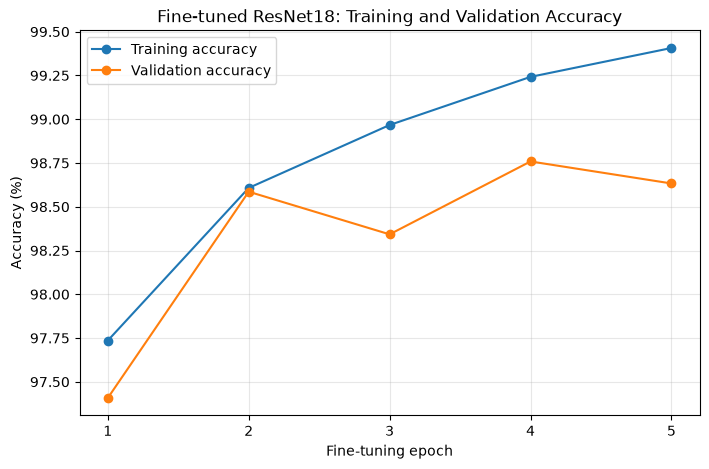

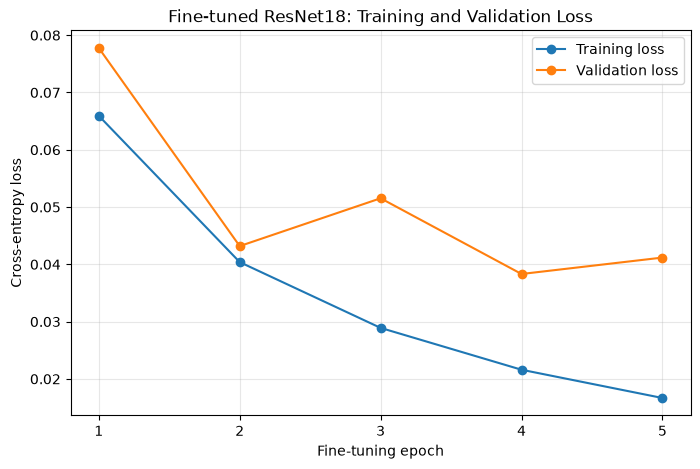

In [9]:
import matplotlib.pyplot as plt

if finetuning_results is not None:
    x = finetuning_results["Epoch"]
    plt.figure(figsize=(8, 5))
    plt.plot(x, finetuning_results["Training accuracy (%)"],
             marker="o", label="Training accuracy")
    plt.plot(x, finetuning_results["Validation accuracy (%)"],
             marker="o", label="Validation accuracy")
    plt.xlabel("Fine-tuning epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Fine-tuned ResNet18: Training and Validation Accuracy")
    plt.xticks(x)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(x, finetuning_results["Training loss"],
             marker="o", label="Training loss")
    plt.plot(x, finetuning_results["Validation loss"],
             marker="o", label="Validation loss")
    plt.xlabel("Fine-tuning epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title("Fine-tuned ResNet18: Training and Validation Loss")
    plt.xticks(x)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
else:
    print("Plots skipped because no saved fine-tuning history was found.")

## 9. Compare Baseline and Fine-Tuned Models


In [12]:
FINETUNED_CANDIDATES = [
    PROJECT_DIR / "best_resnet18_finetuned.pth",
    Path("/kaggle/working/best_resnet18_finetuned.pth"),
    reproduced_checkpoint_path,
]
finetuned_path = next((p for p in FINETUNED_CANDIDATES if p.is_file()), None)

finetuned_model = None
fine_tuned_val_acc = None
if finetuned_path is not None:
    fine_tuned_checkpoint = torch.load(
        finetuned_path, map_location="cpu", weights_only=True
    )
    assert fine_tuned_checkpoint["class_to_idx"] == class_to_idx

    finetuned_model = resnet18(weights=None)
    finetuned_model.fc = nn.Linear(finetuned_model.fc.in_features, num_classes)
    finetuned_model.load_state_dict(fine_tuned_checkpoint["model_state_dict"])
    finetuned_model = finetuned_model.to(DEVICE)
    finetuned_model.eval()

    fine_tuned_val_acc = float(fine_tuned_checkpoint["val_accuracy"])
    print("Fine-tuned checkpoint:", finetuned_path)
    print("Fine-tuned best epoch:", fine_tuned_checkpoint["epoch"])
    print(f"Baseline validation accuracy: {baseline_val_acc * 100:.2f}%")
    print(f"Fine-tuned validation accuracy: {fine_tuned_val_acc * 100:.2f}%")
    print(f"Improvement: {(fine_tuned_val_acc - baseline_val_acc) * 100:+.2f} percentage points")
else:
    print("best_resnet18_finetuned.pth not found. Place the downloaded file in PROJECT_DIR.")

Fine-tuned checkpoint: c:\Users\yzsha\Documents\DataAndAI_project\KaggleCompetitionProject\KaggleCompetitionENGE707\best_resnet18_finetuned.pth
Fine-tuned best epoch: 4
Baseline validation accuracy: 95.98%
Fine-tuned validation accuracy: 98.76%
Improvement: +2.78 percentage points


In [13]:
# Optional clickable download links when using Kaggle and reproducing training.
if IS_KAGGLE and RUN_FULL_FINETUNING:
    from IPython.display import FileLink
    for path in (reproduced_checkpoint_path, reproduced_history_path):
        if path.is_file():
            print(f"Saved: {path.name} ({path.stat().st_size / 1024**2:.2f} MB)")
            display(FileLink(str(path)))
else:
    print("No new training files to download; use your existing local saved files.")

No new training files to download; use your existing local saved files.


## 10. Generate Kaggle Predictions

### 10.1 Load the test dataset

In [14]:
# Locate the shared pipeline and dataset even when fine-tuning is disabled.
create_dataloaders, data_dir = resolve_pipeline_and_data_dir()

# Use the same preprocessing as the original model.
data = create_dataloaders(data_dir=data_dir)

test_loader = data.test_loader
idx_to_class = data.idx_to_class

assert data.class_to_idx == class_to_idx

print("Data folder:", data_dir)
print("Test images:", len(test_loader.dataset))


Test images: 29443


### 10.2 Generate predictions

In [15]:
# Use the best saved fine-tuned model (epoch 4)
assert finetuned_model is not None, "Fine-tuned checkpoint not loaded"

finetuned_model.eval()

predicted_classes = []
predicted_image_ids = []

with torch.no_grad():
    for images, image_ids in test_loader:
        images = images.to(DEVICE)

        outputs = finetuned_model(images)
        predicted_indices = outputs.argmax(dim=1).cpu().tolist()

        predicted_classes.extend(
            idx_to_class[idx] for idx in predicted_indices
        )
        predicted_image_ids.extend(image_ids)

print("Total predictions:", len(predicted_classes))
print("First five predictions:", predicted_classes[:5])

assert len(predicted_classes) == 29443

Total predictions: 29443
First five predictions: ['DogEye', 'DogMouth', 'DogNose', 'DogFace', 'CatMouth']


### 10.3 Create submission

In [16]:
import pandas as pd

sample_submission = pd.read_csv(data_dir / "sample_submission.csv")

prediction_lookup = dict(
    zip(map(str, predicted_image_ids), predicted_classes)
)

submission = sample_submission.copy()

submission["class"] = (
    submission["image_id"].astype(str).map(prediction_lookup)
)

# Verify the submission
assert len(submission) == 29443
assert submission["class"].notna().all()
assert submission["class"].isin(class_to_idx.keys()).all()

# Save separately from the original submission
submission_path = PROJECT_DIR / "submission_finetuned.csv"
submission.to_csv(submission_path, index=False)

print("Saved:", submission_path)
print("Submission shape:", submission.shape)
print(submission.head())


Saved: c:\Users\yzsha\Documents\DataAndAI_project\KaggleCompetitionProject\KaggleCompetitionENGE707\submission_finetuned.csv
Submission shape: (29443, 2)
   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4   DogFace
4         5  CatMouth
